# Reproducing Figure 3 (panels F1, C1, C2) of Keskar et al., ICLR 2017
*On Large-Batch Training for Deep Learning: Generalization Gap and Sharp Minima*

Written only from the paper's text. Protocol (Sec. 1.1 and 2.2): ADAM for both regimes, randomly sampled fixed-size
batches, SB = 256 points, LB = 10% of the training set, train until the training loss stops improving, then plot
f(α·x*_LB + (1−α)·x*_SB) and the accuracy for α ∈ [−1, 2] on the train and test sets.
Image inputs are fed as raw pixel values (Appendix A: no pre-processing).

> **Scope of this reproduction: one trial per network and regime.** The paper runs every configuration 5 times
> and reports mean ± standard deviation (Table 2), then plots one randomly chosen SB/LB pair (Figure 3).
> This notebook trains a single SB model and a single LB model per network (`CFG['n_trials'] = 1`). The numbers
> it prints are single-run values, not means, and should not be read as an exact reproduction of Table 2.
> Set `n_trials` to 5 for the full protocol (about five times the training time).

**Run order:** Runtime → Change runtime type → GPU, then run cells 1 → 9.
**After a disconnect:** run cells 1–5 again, then continue. Cells 6 and 7 resume from the checkpoints and cached results in Drive.
Everything lives in `MyDrive/large_batch_repro/`.

## Cell 1 — Mount Drive, imports, configuration

In [2]:
from google.colab import drive
drive.mount('/content/drive')

import os, json, time, random
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

ROOT       = '/content/drive/MyDrive/large_batch_repro'
DATA_DIR   = os.path.join(ROOT, 'data')
# v3 = C1 overlapping pooling, BN population statistics, longer convergence criterion. New folders, so models
# from earlier versions are never reloaded by mistake. The data cache is reused as is.
CKPT_DIR   = os.path.join(ROOT, 'checkpoints_v3')
RESULT_DIR = os.path.join(ROOT, 'results_v3')
FIG_DIR    = os.path.join(ROOT, 'figures')
for _d in (DATA_DIR, CKPT_DIR, RESULT_DIR, FIG_DIR):
    os.makedirs(_d, exist_ok=True)

assert torch.cuda.is_available(), 'Enable a GPU: Runtime > Change runtime type'
DEVICE = torch.device('cuda')
torch.backends.cudnn.benchmark = True
print('GPU:', torch.cuda.get_device_name(0))

CFG = {
    # ---- Protocol from Sec. 1.1 / 2.2 -------------------------------------
    'networks':    ['F1', 'C1', 'C2'],
    'sb_batch':    256,        # small batch: 256 data points
    'lb_fraction': 0.10,       # large batch: 10% of the training data
    'lr':          1e-3,       # ADAM in both regimes; step size not given in the paper -> ADAM default
    # "trained, without any budget or limits, until the loss function ceased to improve"
    # -> stop when the epoch training loss has not improved (relatively) for `patience` epochs, with a
    #    safety cap. The paper gives no numbers for this. The epoch loss is measured with dropout on and is
    #    noisy, and earlier runs stopped C1/C2 before they converged (C1 SB even hit the cap), so the
    #    criterion is applied identically to all networks with a longer patience and a high cap.
    'max_epochs':  {'SB': 300, 'LB': 300},
    'patience':    20,
    'min_rel_improvement': 1e-3,
    'n_trials':    1,          # SINGLE TRIAL. The paper uses 5 (Table 2 = mean ± std over 5 runs).
    # ---- Figure 3 -----------------------------------------------------------
    'alphas':      [round(-1.0 + 0.1 * i, 2) + 0.0 for i in range(31)],   # step 0.1, contains exactly 0.0 and 1.0
    # Every saved model carries BN *population* statistics computed over the training set with the final
    # weights (Ioffe & Szegedy, 2015, Alg. 2). 'recompute' applies that same definition at every alpha, so the
    # curve uses one convention everywhere and alpha = 0 / 1 reproduce the saved models (checked in Cell 7).
    # 'interpolate' (option) blends the statistics instead, with variances interpolated in log space so
    # extrapolation can never produce a negative variance.
    'bn_mode':     'recompute',
    'eval_batch':  2000,
    # Display only: loss-axis limit of the plots. The paper's own Figure 3/7 loss axes go up to 7-18.
    # Values above it are drawn as markers on the top edge and printed; the saved results are never changed.
    'loss_axis_max': 15.0,
    # ---- Engineering ----------------------------------------------------------
    'use_amp':     True,       # mixed precision for training only (bf16 on A100/L4, fp16 on T4); eval is fp32
    'lb_micro_batch': None,    # None = exact full-batch step. Set e.g. 1250 only if LB on C2 runs out of memory
                               # (gradients are then accumulated, but BN statistics come from the micro-batches).
    'ckpt_every':  1,          # epochs between checkpoints to Drive
}
with open(os.path.join(ROOT, 'config.json'), 'w') as f:
    json.dump(CFG, f, indent=2)
print('Working directory in Drive:', ROOT)

Mounted at /content/drive
GPU: Tesla T4
Working directory in Drive: /content/drive/MyDrive/large_batch_repro


## Cell 2 — Download the datasets into Drive (once) and cache them as compact `.npz` files in Drive

In [3]:
import torchvision

DATASET_OF = {'F1': 'MNIST', 'C1': 'CIFAR10', 'C2': 'CIFAR10'}

def prepare_dataset(name):
    cache = os.path.join(DATA_DIR, f'{name}.npz')
    if os.path.exists(cache):
        print(f'{name}: cached at {cache}')
        return
    raw = os.path.join(DATA_DIR, 'raw')            # raw downloads also live in Drive
    if name == 'MNIST':
        tr = torchvision.datasets.MNIST(raw, train=True, download=True)
        te = torchvision.datasets.MNIST(raw, train=False, download=True)
        x_train, y_train = tr.data.numpy(), tr.targets.numpy()          # (N,28,28) uint8
        x_test,  y_test  = te.data.numpy(), te.targets.numpy()
    elif name == 'CIFAR10':
        tr = torchvision.datasets.CIFAR10(raw, train=True, download=True)
        te = torchvision.datasets.CIFAR10(raw, train=False, download=True)
        x_train, y_train = tr.data.transpose(0, 3, 1, 2), np.array(tr.targets)   # (N,3,32,32) uint8
        x_test,  y_test  = te.data.transpose(0, 3, 1, 2), np.array(te.targets)
    else:
        raise ValueError(name)
    tmp = cache[:-4] + '_tmp.npz'
    np.savez(tmp,
             x_train=np.ascontiguousarray(x_train, dtype=np.uint8), y_train=y_train.astype(np.int64),
             x_test=np.ascontiguousarray(x_test, dtype=np.uint8),   y_test=y_test.astype(np.int64))
    os.replace(tmp, cache)
    print(f'{name}: train {x_train.shape}, test {x_test.shape} -> {cache}')

for ds in sorted({DATASET_OF[n] for n in CFG['networks']}):
    prepare_dataset(ds)

CIFAR10: cached at /content/drive/MyDrive/large_batch_repro/data/CIFAR10.npz
MNIST: cached at /content/drive/MyDrive/large_batch_repro/data/MNIST.npz


## Cell 3 — Load the cached data from Drive straight onto the GPU
The data sets are small, so they are kept on the GPU as `uint8` and random batches are taken by indexing,
which is far faster than a DataLoader for the 256-sample regime. Appendix A says the image data sets are used
without any pre-processing, so the raw pixel values (0–255) are fed to the networks, only cast to float.

In [4]:
_GPU_DATA = {}

def get_data(ds_name):
    if ds_name not in _GPU_DATA:
        z = np.load(os.path.join(DATA_DIR, f'{ds_name}.npz'))
        _GPU_DATA[ds_name] = {k: torch.from_numpy(z[k]).to(DEVICE) for k in z.files}
    return _GPU_DATA[ds_name]

def to_input(x_u8, ds_name):
    x = x_u8.float()                                     # raw pixel values, no scaling or normalisation
    return x.flatten(1) if ds_name == 'MNIST' else x    # MNIST -> 784-dim vectors for the MLP

for ds in sorted({DATASET_OF[n] for n in CFG['networks']}):
    d = get_data(ds)
    print(ds, {k: tuple(v.shape) for k, v in d.items()})

CIFAR10 {'x_train': (50000, 3, 32, 32), 'y_train': (50000,), 'x_test': (10000, 3, 32, 32), 'y_test': (10000,)}
MNIST {'x_train': (60000, 28, 28), 'y_train': (60000,), 'x_test': (10000, 28, 28), 'y_test': (10000,)}


## Cell 4 — Networks (Appendix B)
* **F1** (B.1): 784 → 5 × [Linear 512, BN, ReLU] → 10.
* **C1** (B.3): 2 × [64, 5, 5, 2]–MaxPool(3), i.e. 64 filters, 5×5 kernel, stride 2, followed by MaxPool(3);
  then Dense 384 → Dense 192 → 10, BN on all layers, ReLU, dropout with retention 0.5 on the two dense layers.
  B.3 gives the pooling window (3) but not its stride. It describes C1 as a modified version of the AlexNet
  configuration it cites (Krizhevsky et al., 2012), whose pooling is *overlapping* 3×3 pooling with stride 2
  (their Sec. 3.4); likewise C2's MaxPool(2) follows its cited VGG (2×2, stride 2). So MaxPool(3) is 3×3, stride 2.
  The earlier stride-3 reading was not supported by either reference and collapsed the feature map to 1×1
  (64 features into the 384-unit layer). The flattened size is computed from the layers (it comes out as 256).
* **Padding** is the one thing B.3/B.4 never state. It cannot be zero: without padding C1's second 5×5 convolution
  would receive a 4×4 map, and C2's 13 convolutions would shrink 32×32 below 1×1. Both networks therefore use
  padding = kernel // 2 (the smallest symmetric padding that keeps the stated layers valid). C1's pooling layers use
  the same 'same'-style padding (1), so every C1 layer halves the map: 32 → 16 → 8 → 4 → 2.
* **C2** (B.4): VGG stacks 2×64, 2×128, 3×256, 3×512, 3×512 (3×3, stride 1), MaxPool(2) after each stack → Dense 512 → 10,
  same BN/ReLU/dropout as C1.

BN is placed between the affine map and the ReLU and is not applied to the output layer (softmax is inside the cross-entropy).
Default PyTorch initialisation is uniform, matching "uniformly distributed random starting points".

In [5]:
def fc_bn_relu(i, o):
    return [nn.Linear(i, o), nn.BatchNorm1d(o), nn.ReLU(inplace=True)]

def conv_bn_relu(cin, cout, k, stride):
    return [nn.Conv2d(cin, cout, k, stride=stride, padding=k // 2), nn.BatchNorm2d(cout), nn.ReLU(inplace=True)]

def build_F1(num_classes=10):
    layers, d = [], 784
    for _ in range(5):
        layers += fc_bn_relu(d, 512)
        d = 512
    layers.append(nn.Linear(d, num_classes))
    return nn.Sequential(*layers)

def build_C1(num_classes=10):
    layers, c = [], 3
    for _ in range(2):
        layers += conv_bn_relu(c, 64, 5, 2)
        layers.append(nn.MaxPool2d(kernel_size=3, stride=2, padding=1))   # AlexNet overlapping pooling
        c = 64
    # flattened size from the layers themselves (32 -> 16 -> 8 -> 4 -> 2, so 256); eval mode leaves BN stats untouched
    features = nn.Sequential(*layers).eval()
    with torch.no_grad():
        n_flat = features(torch.zeros(1, 3, 32, 32)).numel()
    layers += [nn.Flatten(),
               *fc_bn_relu(n_flat, 384), nn.Dropout(0.5),
               *fc_bn_relu(384, 192),        nn.Dropout(0.5),
               nn.Linear(192, num_classes)]
    return nn.Sequential(*layers)

def build_C2(num_classes=10):
    layers, c = [], 3
    for n, width in [(2, 64), (2, 128), (3, 256), (3, 512), (3, 512)]:
        for _ in range(n):
            layers += conv_bn_relu(c, width, 3, 1)
            c = width
        layers.append(nn.MaxPool2d(2))
    # spatial size 32 -> 1 after five poolings, so 512 features
    layers += [nn.Flatten(), *fc_bn_relu(512, 512), nn.Dropout(0.5), nn.Linear(512, num_classes)]
    return nn.Sequential(*layers)

def build_model(net):
    return {'F1': build_F1, 'C1': build_C1, 'C2': build_C2}[net]()

for net in CFG['networks']:
    m = build_model(net).to(DEVICE).eval()
    x = torch.zeros(4, 784) if net == 'F1' else torch.zeros(4, 3, 32, 32)
    with torch.no_grad():
        out = m(x.to(DEVICE))
    print(f'{net}: {sum(p.numel() for p in m.parameters()):,} parameters, output {tuple(out.shape)}')
del m

F1: 1,462,794 parameters, output (4, 10)
C1: 283,274 parameters, output (4, 10)
C2: 14,991,946 parameters, output (4, 10)


## Cell 5 — Training with checkpoint/resume in Drive
* SB and LB runs of the same trial start from the **same** initial point x0 (the paper compares ‖x*−x0‖ for both),
  but use different batch orders.
* Each epoch is a random permutation cut into fixed-size batches (|B_k| constant), leftovers are dropped.
* A checkpoint (`last.pt`: weights, ADAM state, scaler, RNG state, history) is written to Drive every epoch,
  and `final.pt` when the run ends. A finished run is never retrained.
* **BN statistics of the final model.** During training PyTorch keeps an exponential moving average of the batch
  statistics, collected while dropout is active. In C1 a BN layer sits right after a dropout layer, so those
  averages do not describe the network that is evaluated (dropout off); run 1 showed this cost C1 up to 5 points
  of training accuracy. Batch normalization as defined in the paper the authors cite (Ioffe & Szegedy, 2015,
  Alg. 2) uses population statistics computed over the training set with the trained weights. That is done once
  at the end of training, with dropout off, before the final evaluation and before saving.

In [6]:
NET_ID = {'F1': 1, 'C1': 2, 'C2': 3}

def init_seed(net, trial):            # shared by SB and LB of a trial -> same x0
    return 1000 * NET_ID[net] + trial

def data_seed(net, trial, regime):
    return 10 * init_seed(net, trial) + (1 if regime == 'LB' else 2)

def run_dir(net, regime, trial):
    d = os.path.join(CKPT_DIR, f'{net}_{regime}_trial{trial}')
    os.makedirs(d, exist_ok=True)
    return d

def atomic_torch_save(obj, path):
    tmp = path + '.tmp'
    torch.save(obj, tmp)
    os.replace(tmp, path)

def atomic_json_save(obj, path):
    tmp = path + '.tmp'
    with open(tmp, 'w') as f:
        json.dump(obj, f, indent=1)
    os.replace(tmp, path)

def amp_dtype():
    return torch.bfloat16 if torch.cuda.get_device_capability()[0] >= 8 else torch.float16

@torch.no_grad()
def evaluate(model, x_all, y_all, ds_name, bs=None):
    """Mean cross-entropy f(x) and accuracy (%) over a whole data set; eval mode, fp32."""
    bs = bs or CFG['eval_batch']
    model.eval()
    loss_sum = torch.zeros((), device=DEVICE, dtype=torch.float64)
    correct = torch.zeros((), device=DEVICE, dtype=torch.long)
    for i in range(0, len(y_all), bs):
        xb, yb = to_input(x_all[i:i + bs], ds_name), y_all[i:i + bs]
        out = model(xb).float()
        loss_sum += F.cross_entropy(out, yb, reduction='sum').double()
        correct += (out.argmax(1) == yb).sum()
    n = len(y_all)
    return loss_sum.item() / n, 100.0 * correct.item() / n

BN_TYPES = (nn.BatchNorm1d, nn.BatchNorm2d)

@torch.no_grad()
def recompute_bn_stats(model, x_all, ds_name, bs=None):
    """BN population statistics for the current weights: mean of the per-batch means and unbiased variances over
    the whole training set, in a fixed order (Ioffe & Szegedy 2015, Alg. 2). Dropout stays off."""
    bs = bs or CFG['eval_batch']
    bns = [m for m in model.modules() if isinstance(m, BN_TYPES)]
    for m in bns:
        m.reset_running_stats()
        m.momentum = None                     # cumulative average over all batches
    model.eval()
    for m in bns:
        m.train()
    for i in range(0, len(x_all), bs):
        model(to_input(x_all[i:i + bs], ds_name))
    for m in bns:
        m.momentum = 0.1
    model.eval()

def train_run(net, regime, trial):
    d = run_dir(net, regime, trial)
    final_path, last_path = os.path.join(d, 'final.pt'), os.path.join(d, 'last.pt')
    if os.path.exists(final_path):
        ck = torch.load(final_path, map_location='cpu', weights_only=False)
        m = ck['metrics']
        print(f'[{net} {regime} t{trial}] cached: train acc {m["train_acc"]:.2f}%, test acc {m["test_acc"]:.2f}% '
              f'({ck["epochs"]} epochs, batch {ck["batch_size"]})')
        return ck

    ds = DATASET_OF[net]
    data = get_data(ds)
    xtr, ytr, xte, yte = data['x_train'], data['y_train'], data['x_test'], data['y_test']
    N = len(ytr)
    B = CFG['sb_batch'] if regime == 'SB' else int(round(CFG['lb_fraction'] * N))
    steps = N // B
    micro = CFG['lb_micro_batch'] if regime == 'LB' else None

    torch.manual_seed(init_seed(net, trial))
    model = build_model(net).to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=CFG['lr'])
    dt, use_amp = amp_dtype(), CFG['use_amp']
    scaler = torch.amp.GradScaler('cuda', enabled=use_amp and dt == torch.float16)
    gen = torch.Generator(device=DEVICE)
    gen.manual_seed(data_seed(net, trial, regime))
    st = {'epoch': 0, 'best': float('inf'), 'bad': 0, 'history': []}

    if os.path.exists(last_path):
        ck = torch.load(last_path, map_location='cpu', weights_only=False)
        model.load_state_dict(ck['model'])
        opt.load_state_dict(ck['opt'])
        scaler.load_state_dict(ck['scaler'])
        gen.set_state(ck['gen'])
        st = ck['st']
        print(f'[{net} {regime} t{trial}] resuming after epoch {st["epoch"]}')
    else:
        print(f'[{net} {regime} t{trial}] new run: batch {B}, {steps} steps/epoch')

    max_ep = CFG['max_epochs'][regime]
    stopped = st['bad'] >= CFG['patience']
    while st['epoch'] < max_ep and not stopped:
        model.train()
        t0 = time.time()
        perm = torch.randperm(N, device=DEVICE, generator=gen)
        loss_sum = torch.zeros((), device=DEVICE)
        correct = torch.zeros((), device=DEVICE, dtype=torch.long)
        for s in range(steps):
            idx = perm[s * B:(s + 1) * B]
            opt.zero_grad(set_to_none=True)
            for ch in (idx.split(micro) if micro else (idx,)):
                xb, yb = to_input(xtr[ch], ds), ytr[ch]
                with torch.autocast('cuda', dtype=dt, enabled=use_amp):
                    out = model(xb)
                loss = F.cross_entropy(out.float(), yb)
                scaler.scale(loss * (len(ch) / B)).backward()
                loss_sum += loss.detach() * len(ch)
                correct += (out.argmax(1) == yb).sum()
            scaler.step(opt)
            scaler.update()

        tr_loss = loss_sum.item() / (steps * B)
        tr_acc = 100.0 * correct.item() / (steps * B)
        if not np.isfinite(tr_loss):
            raise RuntimeError('Training loss is not finite')
        te_loss, te_acc = evaluate(model, xte, yte, ds)
        st['epoch'] += 1
        if tr_loss < st['best'] * (1.0 - CFG['min_rel_improvement']):
            st['best'], st['bad'] = tr_loss, 0
        else:
            st['bad'] += 1
        stopped = st['bad'] >= CFG['patience']
        st['history'].append({'epoch': st['epoch'], 'train_loss_running': tr_loss, 'train_acc_running': tr_acc,
                              'test_loss': te_loss, 'test_acc': te_acc, 'seconds': time.time() - t0})
        print(f'  ep {st["epoch"]:3d} | train loss {tr_loss:.4f} acc {tr_acc:6.2f}% | '
              f'test acc {te_acc:6.2f}% | no-improve {st["bad"]:2d} | {time.time() - t0:5.1f}s')
        if st['epoch'] % CFG['ckpt_every'] == 0 or stopped or st['epoch'] == max_ep:
            atomic_torch_save({'model': model.state_dict(), 'opt': opt.state_dict(),
                               'scaler': scaler.state_dict(), 'gen': gen.get_state(), 'st': st}, last_path)

    recompute_bn_stats(model, xtr, ds)        # population statistics with the final weights (see above)
    tr_loss, tr_acc = evaluate(model, xtr, ytr, ds)
    te_loss, te_acc = evaluate(model, xte, yte, ds)
    ck = {'state_dict': {k: v.detach().cpu() for k, v in model.state_dict().items()},
          'metrics': {'train_loss': tr_loss, 'train_acc': tr_acc, 'test_loss': te_loss, 'test_acc': te_acc},
          'batch_size': B, 'epochs': st['epoch'], 'history': st['history'],
          'stopped_by': 'plateau' if stopped else 'max_epochs', 'bn_stats': 'population'}
    atomic_torch_save(ck, final_path)
    atomic_json_save({k: ck[k] for k in ('metrics', 'batch_size', 'epochs', 'stopped_by', 'history')},
                     os.path.join(d, 'summary.json'))
    if os.path.exists(last_path):
        os.remove(last_path)
    print(f'[{net} {regime} t{trial}] done ({ck["stopped_by"]}): train acc {tr_acc:.2f}%, test acc {te_acc:.2f}%')
    return ck

## Cell 6 — Train the SB and LB models
Re-running this cell after a disconnect resumes unfinished runs and simply loads finished ones.
To spread the work over sessions, set `CFG['networks']` to one network at a time.

In [7]:
TRAINED = {}
for net in CFG['networks']:
    for trial in range(CFG['n_trials']):
        for regime in ('SB', 'LB'):
            TRAINED[(net, regime, trial)] = train_run(net, regime, trial)
            torch.cuda.empty_cache()

[F1 SB t0] new run: batch 256, 234 steps/epoch
  ep   1 | train loss 0.1826 acc  94.44% | test acc  96.88% | no-improve  0 |   1.5s
  ep   2 | train loss 0.0821 acc  97.46% | test acc  97.47% | no-improve  0 |   1.0s
  ep   3 | train loss 0.0546 acc  98.33% | test acc  97.94% | no-improve  0 |   1.0s
  ep   4 | train loss 0.0444 acc  98.59% | test acc  98.04% | no-improve  0 |   0.9s
  ep   5 | train loss 0.0349 acc  98.89% | test acc  97.85% | no-improve  0 |   1.0s
  ep   6 | train loss 0.0274 acc  99.13% | test acc  98.03% | no-improve  0 |   1.0s
  ep   7 | train loss 0.0263 acc  99.14% | test acc  97.91% | no-improve  0 |   0.9s
  ep   8 | train loss 0.0228 acc  99.25% | test acc  98.16% | no-improve  0 |   0.9s
  ep   9 | train loss 0.0192 acc  99.33% | test acc  97.96% | no-improve  0 |   1.0s
  ep  10 | train loss 0.0185 acc  99.41% | test acc  97.98% | no-improve  0 |   1.0s
  ep  11 | train loss 0.0138 acc  99.53% | test acc  97.72% | no-improve  0 |   1.0s
  ep  12 | train l

## Cell 7 — Parametric 1-D plots: f(α·x*_LB + (1−α)·x*_SB), α ∈ [−1, 2]
For every α the loss and accuracy are measured on the full training and test sets. Each α is saved to a JSON file in
Drive as soon as it is computed, so an interrupted sweep continues where it stopped.

**Batch norm along the line.** The weights are interpolated; BN population statistics are recomputed for each
interpolated network exactly as they were for the saved models at the end of training (Cell 5). One definition is
therefore used at every α, including outside [0, 1]. The previous version interpolated the statistics instead:
outside [0, 1] that extrapolation drove variances to zero or below, which blew activations up and produced the
huge losses and NaNs.

**Endpoints.** α = 0 and α = 1 load the saved SB and LB models unchanged. After the sweep two checks run:
(1) the endpoint values equal the direct evaluation stored with each saved model, and (2) recomputing the BN
statistics at the endpoints reproduces the saved models, which shows the recomputation used for the other α does
not shift the curve. The cell stops with an error if either check fails.

**Unstable points.** Any non-finite loss is stored as NaN, flagged in the printout, and marked in the plot.

In [8]:
def interpolate(sd_s, sd_l, alpha):
    out = {}
    for k, vs in sd_s.items():
        vl = sd_l[k]
        if not torch.is_floating_point(vs):   # num_batches_tracked
            out[k] = vs.clone()
        elif k.endswith('running_var'):       # only used by bn_mode='interpolate': log space, stays positive
            out[k] = torch.exp(alpha * torch.log(vl.clamp_min(1e-12)) + (1.0 - alpha) * torch.log(vs.clamp_min(1e-12)))
        else:
            out[k] = alpha * vl + (1.0 - alpha) * vs
    return out

def pick_pair(net):
    """'we randomly chose a pair of SB and LB minimizers from the 5 trials'"""
    rng = random.Random(NET_ID[net])
    return rng.randrange(CFG['n_trials']), rng.randrange(CFG['n_trials'])

def eval_point(model, data, ds):
    tr_loss, tr_acc = evaluate(model, data['x_train'], data['y_train'], ds)
    te_loss, te_acc = evaluate(model, data['x_test'], data['y_test'], ds)
    return {'train_loss': tr_loss, 'train_acc': tr_acc, 'test_loss': te_loss, 'test_acc': te_acc}

def parametric_sweep(net):
    ts, tl = pick_pair(net)
    mode = CFG['bn_mode']
    path = os.path.join(RESULT_DIR, f'fig3_{net}_SBt{ts}_LBt{tl}_{mode}.json')
    res = {}
    if os.path.exists(path):
        with open(path) as f:
            res = json.load(f)
    assert 0.0 in CFG['alphas'] and 1.0 in CFG['alphas'], 'alpha grid must contain 0 and 1'
    todo = [a for a in CFG['alphas'] if f'{a:.2f}' not in res]
    print(f'{net}: SB trial {ts}, LB trial {tl}, {len(res)} cached / {len(todo)} to compute')

    load = lambda r, t: torch.load(os.path.join(run_dir(net, r, t), 'final.pt'),
                                   map_location='cpu', weights_only=False)
    ck_s, ck_l = load('SB', ts), load('LB', tl)
    for ck in (ck_s, ck_l):
        assert ck.get('bn_stats') == 'population', 'checkpoint from an older notebook version'
    ds = DATASET_OF[net]
    data = get_data(ds)
    sd_s = {k: v.to(DEVICE) for k, v in ck_s['state_dict'].items()}
    sd_l = {k: v.to(DEVICE) for k, v in ck_l['state_dict'].items()}
    model = build_model(net).to(DEVICE)

    for a in todo:
        t0 = time.time()
        if a == 0.0:                          # exactly the saved SB model
            model.load_state_dict(sd_s)
        elif a == 1.0:                        # exactly the saved LB model
            model.load_state_dict(sd_l)
        else:
            model.load_state_dict(interpolate(sd_s, sd_l, a))
            if mode == 'recompute':
                recompute_bn_stats(model, data['x_train'], ds)
        r = eval_point(model, data, ds)
        finite = all(np.isfinite(r[k]) for k in ('train_loss', 'test_loss'))
        res[f'{a:.2f}'] = {'alpha': a, **r, 'finite': finite}
        atomic_json_save(res, path)
        print(f'  alpha {a:+.2f} | train {r["train_loss"]:9.4f} / {r["train_acc"]:6.2f}% | '
              f'test {r["test_loss"]:9.4f} / {r["test_acc"]:6.2f}% | {time.time() - t0:4.1f}s'
              + ('' if finite else '  <-- NON-FINITE LOSS'))

    check_endpoints(net, res, ck_s['metrics'], ck_l['metrics'])
    if mode == 'recompute':
        check_recompute_at_endpoints(net, model, data, ds, sd_s, sd_l, ck_s['metrics'], ck_l['metrics'])
    return res

def _compare(label, got, ref, acc_tol=0.02, loss_rtol=1e-4):
    bad = []
    for split in ('train', 'test'):
        da = abs(got[f'{split}_acc'] - ref[f'{split}_acc'])
        dl = abs(got[f'{split}_loss'] - ref[f'{split}_loss']) / max(abs(ref[f'{split}_loss']), 1e-12)
        ok = da <= acc_tol and dl <= loss_rtol
        print(f'  {label:34} {split:5}: {got[f"{split}_acc"]:6.2f}% vs saved {ref[f"{split}_acc"]:6.2f}% | '
              f'loss {got[f"{split}_loss"]:.5f} vs {ref[f"{split}_loss"]:.5f} -> {"OK" if ok else "MISMATCH"}')
        if not ok:
            bad.append(f'{label} {split}')
    return bad

def check_endpoints(net, res, m_sb, m_lb):
    """(1) Endpoint values of the sweep must equal the direct evaluation of the saved models."""
    bad = _compare(f'{net} sweep alpha=0 (SB)', res['0.00'], m_sb) + _compare(f'{net} sweep alpha=1 (LB)', res['1.00'], m_lb)
    if bad:
        raise AssertionError(f'{net}: endpoint mismatch for {bad}. Results are cached; investigate before plotting.')

def check_recompute_at_endpoints(net, model, data, ds, sd_s, sd_l, m_sb, m_lb):
    """(2) Recomputing BN statistics at the endpoints must reproduce the saved models."""
    bad = []
    for label, sd, ref in ((f'{net} recomputed BN at alpha=0', sd_s, m_sb), (f'{net} recomputed BN at alpha=1', sd_l, m_lb)):
        model.load_state_dict(sd)
        recompute_bn_stats(model, data['x_train'], ds)
        bad += _compare(label, eval_point(model, data, ds), ref)
    if bad:
        raise AssertionError(f'{net}: BN recomputation does not reproduce the saved models: {bad}')

FIG3 = {net: parametric_sweep(net) for net in CFG['networks']}

F1: SB trial 0, LB trial 0, 0 cached / 31 to compute
  alpha -1.00 | train    0.0085 /  99.79% | test    0.0997 /  97.87% |  0.2s
  alpha -0.90 | train    0.0052 /  99.89% | test    0.0952 /  98.06% |  0.2s
  alpha -0.80 | train    0.0030 /  99.93% | test    0.0916 /  98.17% |  0.2s
  alpha -0.70 | train    0.0017 /  99.96% | test    0.0888 /  98.26% |  0.2s
  alpha -0.60 | train    0.0009 /  99.97% | test    0.0867 /  98.35% |  0.2s
  alpha -0.50 | train    0.0005 /  99.99% | test    0.0850 /  98.42% |  0.2s
  alpha -0.40 | train    0.0003 /  99.99% | test    0.0836 /  98.43% |  0.2s
  alpha -0.30 | train    0.0002 / 100.00% | test    0.0824 /  98.48% |  0.2s
  alpha -0.20 | train    0.0001 / 100.00% | test    0.0817 /  98.50% |  0.2s
  alpha -0.10 | train    0.0001 / 100.00% | test    0.0810 /  98.51% |  0.2s
  alpha +0.00 | train    0.0001 / 100.00% | test    0.0800 /  98.53% |  0.1s
  alpha +0.10 | train    0.0001 / 100.00% | test    0.0790 /  98.52% |  0.2s
  alpha +0.20 | train  

## Cell 8 — Plot the panels in the style of Figure 3
Left axis (blue): cross-entropy. Right axis (red): accuracy. Solid = training set, dashed = test set.
α = 0 is the SB minimizer, α = 1 the LB minimizer. Figures are saved to Drive.

The loss axis is limited to `CFG['loss_axis_max']` (display only). Losses above it are drawn as ▲ on the top edge,
non-finite losses as ✕, and both are listed under the plot with their real values. Accuracy is always shown in full.

/tmp/ipykernel_1765/1933430397.py:46: UserWarning: Tight layout not applied. tight_layout cannot make Axes width small enough to accommodate all Axes decorations
  fig.tight_layout()


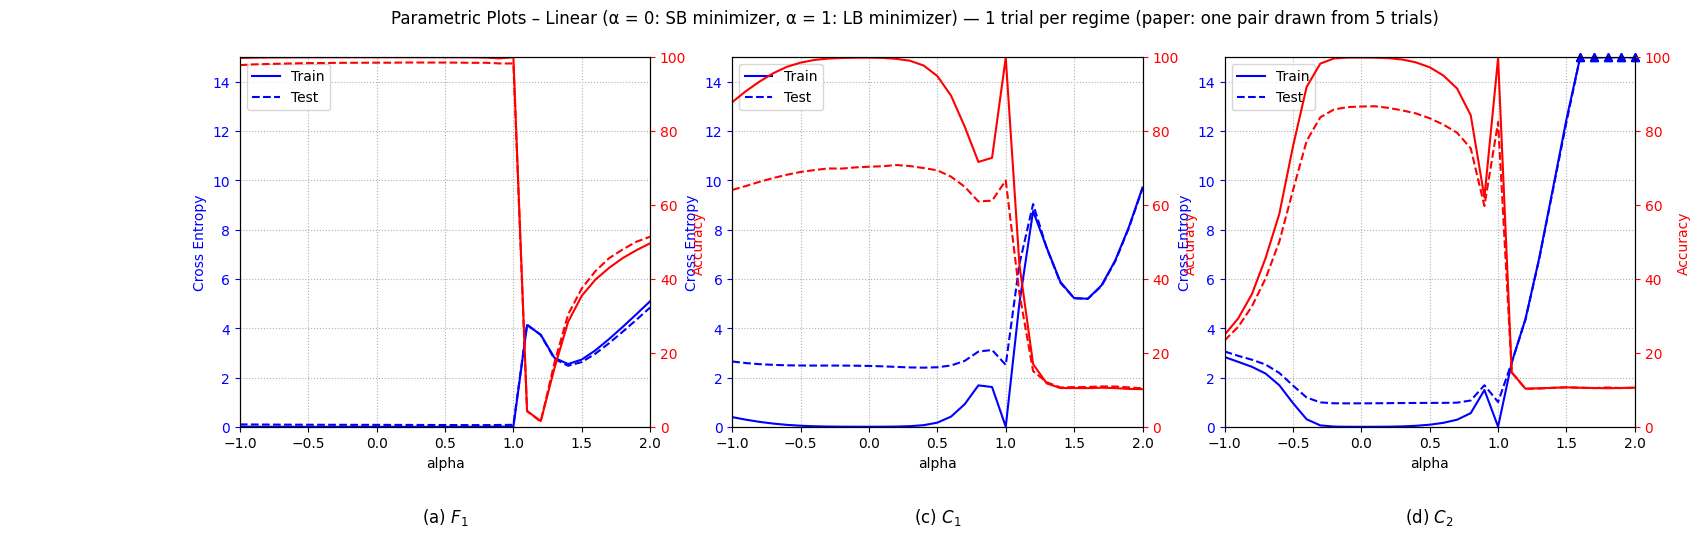

C2: values beyond the loss axis (15) -> train loss 15.8 at α=+1.6; train loss 19.3 at α=+1.7; train loss 22.8 at α=+1.8; train loss 26.6 at α=+1.9; train loss 30.5 at α=+2.0; test loss 15.7 at α=+1.6; test loss 19.1 at α=+1.7; test loss 22.5 at α=+1.8; test loss 26.3 at α=+1.9; test loss 30.2 at α=+2.0


In [9]:
import matplotlib.pyplot as plt

PANEL = {'F1': '(a) $F_1$', 'C1': '(c) $C_1$', 'C2': '(d) $C_2$'}

def plot_panel(ax, res, title, cap):
    keys = sorted(res, key=float)
    a = np.array([float(k) for k in keys])
    get = lambda field: np.array([res[k][field] for k in keys], dtype=float)
    notes = []
    handles = []
    for field, style, label in (('train_loss', '-', 'Train'), ('test_loss', '--', 'Test')):
        y = get(field)
        bad = ~np.isfinite(y)
        over = np.isfinite(y) & (y > cap)
        shown = np.where(bad, np.nan, np.minimum(y, cap))           # NaN breaks the line at unstable points
        h, = ax.plot(a, shown, 'b' + style, label=label)
        handles.append(h)
        ax.plot(a[over], np.full(over.sum(), cap), 'b^', ms=6, clip_on=False)
        ax.plot(a[bad], np.full(bad.sum(), cap), 'bx', ms=7, mew=2, clip_on=False)
        notes += [f'{label.lower()} loss {y[i]:.3g} at α={a[i]:+.1f}' for i in np.where(over)[0]]
        notes += [f'{label.lower()} loss non-finite at α={a[i]:+.1f}' for i in np.where(bad)[0]]
    ax.set_xlim(-1, 2)
    ax.set_ylim(0, cap)
    ax.set_xlabel('alpha')
    ax.set_ylabel('Cross Entropy', color='b')
    ax.tick_params(axis='y', colors='b')
    ax.grid(True, linestyle=':')
    ax2 = ax.twinx()
    ax2.plot(a, get('train_acc'), 'r-')
    ax2.plot(a, get('test_acc'), 'r--')
    ax2.set_ylim(0, 100)
    ax2.set_ylabel('Accuracy', color='r')
    ax2.tick_params(axis='y', colors='r')
    ax.legend(handles=handles, loc='upper left')
    ax.set_title(title, y=-0.28)
    return notes

nets = [n for n in CFG['networks'] if n in FIG3]
cap = CFG['loss_axis_max']
fig, axes = plt.subplots(1, len(nets), figsize=(6 * len(nets), 4.8), squeeze=False)
all_notes = {}
for ax, net in zip(axes[0], nets):
    all_notes[net] = plot_panel(ax, FIG3[net], PANEL.get(net, net), cap)
fig.suptitle(f'Parametric Plots – Linear (α = 0: SB minimizer, α = 1: LB minimizer) — '
             f'{CFG["n_trials"]} trial per regime (paper: one pair drawn from 5 trials)')
fig.tight_layout()
for ext in ('png', 'pdf'):
    fig.savefig(os.path.join(FIG_DIR, f'figure3_{"_".join(nets)}_{CFG["bn_mode"]}.{ext}'),
                dpi=200, bbox_inches='tight')
plt.show()
for net, notes in all_notes.items():
    if notes:
        print(f'{net}: values beyond the loss axis ({cap:g}) -> ' + '; '.join(notes))

## Cell 9 — Comparison with Table 2 and the ‖x* − x0‖ ratio from Section 3
**Single-trial values.** Each "ours" number comes from one training run. The paper's numbers are means ± standard
deviations over 5 runs, so a difference of a point or two is within what one run can vary by and is not evidence of
a mismatch. With `n_trials` > 1 the table shows our mean ± std as well.

In [10]:
PAPER_T2 = {  # (mean, std) for SB train, LB train, SB test, LB test (Table 2, 5 trials)
    'F1': ((99.66, 0.05), (99.92, 0.01), (98.03, 0.07), (97.81, 0.07)),
    'C1': ((99.89, 0.02), (99.66, 0.20), (80.04, 0.12), (77.26, 0.42)),
    'C2': ((99.99, 0.04), (99.99, 0.01), (89.24, 0.12), (87.26, 0.07)),
}

def param_vector(state_dict, names):
    return torch.cat([state_dict[k].float().flatten().cpu() for k in names])

def fmt(vals):
    vals = np.array(vals)
    return f'{vals.mean():6.2f}' + (f' ± {vals.std(ddof=1):4.2f}' if len(vals) > 1 else '       ')

n = CFG['n_trials']
print(f'Accuracies in %. Ours: {n} trial(s) per regime' + (' (single run, not a mean)' if n == 1 else ' (mean ± std)')
      + '. Paper: mean ± std over 5 trials.\n')
cols = [('train SB', 'SB', 'train_acc', 0), ('train LB', 'LB', 'train_acc', 1),
        ('test SB', 'SB', 'test_acc', 2), ('test LB', 'LB', 'test_acc', 3)]
print(f'{"net":4} {"":5} | ' + ' | '.join(f'{c[0]:>14}' for c in cols) + ' | ||xs-x0||/||xl-x0||')
for net in CFG['networks']:
    runs = {r: [TRAINED.get((net, r, t)) or train_run(net, r, t) for t in range(n)] for r in ('SB', 'LB')}
    ratios = []
    for t in range(n):
        torch.manual_seed(init_seed(net, t))
        m0 = build_model(net)
        names = [k for k, _ in m0.named_parameters()]
        x0 = param_vector(m0.state_dict(), names)
        xs = param_vector(runs['SB'][t]['state_dict'], names)
        xl = param_vector(runs['LB'][t]['state_dict'], names)
        ratios.append(((xs - x0).norm() / (xl - x0).norm()).item())
    ours = [fmt([ck['metrics'][key] for ck in runs[r]]) for _, r, key, _ in cols]
    paper = [f'{PAPER_T2[net][i][0]:6.2f} ± {PAPER_T2[net][i][1]:4.2f}' for *_, i in cols]
    print(f'{net:4} {"ours":5} | ' + ' | '.join(f'{v:>14}' for v in ours) + f' | {fmt(ratios)}')
    print(f'{"":4} {"paper":5} | ' + ' | '.join(f'{v:>14}' for v in paper) + ' | 3-10 (Sec. 3)')
    print(f'{"":4} {"gap":5} | ' + ' | '.join(f'{np.mean([ck["metrics"][key] for ck in runs[r]]) - PAPER_T2[net][i][0]:>+14.2f}'
                                             for _, r, key, i in cols) + ' |')
    stops = ', '.join(f'{r}: {ck["epochs"]} ep ({ck["stopped_by"]})' for r in ('SB', 'LB') for ck in runs[r])
    print(f'{"":4} {"stop":5} | {stops}\n')

Accuracies in %. Ours: 1 trial(s) per regime (single run, not a mean). Paper: mean ± std over 5 trials.

net        |       train SB |       train LB |        test SB |        test LB | ||xs-x0||/||xl-x0||
F1   ours  |  100.00        |  100.00        |   98.53        |   98.31        |  17.39       
     paper |   99.66 ± 0.05 |   99.92 ± 0.01 |   98.03 ± 0.07 |   97.81 ± 0.07 | 3-10 (Sec. 3)
     gap   |          +0.34 |          +0.08 |          +0.50 |          +0.50 |
     stop  | SB: 147 ep (plateau), LB: 300 ep (max_epochs)

C1   ours  |   99.90        |   99.91        |   70.38        |   66.64        |   4.26       
     paper |   99.89 ± 0.02 |   99.66 ± 0.20 |   80.04 ± 0.12 |   77.26 ± 0.42 | 3-10 (Sec. 3)
     gap   |          +0.01 |          +0.25 |          -9.66 |         -10.62 |
     stop  | SB: 198 ep (plateau), LB: 153 ep (plateau)

C2   ours  |   99.94        |   99.77        |   86.67        |   82.47        |  14.02       
     paper |   99.99 ± 0.04 |   99.99 ± 